In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

In [25]:
data=pd.read_csv('preprocessing.csv')

In [26]:
data.head()

,scholarship_received,placement_status,starting_salary_usd,gpa_or_score,test_score,origin_country_Finland,origin_country_Germany,origin_country_India,origin_country_Ireland,origin_country_Russia,...,visa_status_Schengen Student Visa,visa_status_Student Visa,visa_status_Study Permit,visa_status_Tier 4,post_graduation_visa_OPT,post_graduation_visa_PSW,post_graduation_visa_Post-Study Visa,post_graduation_visa_Work Permit,study_duration,Salary_Bin
0,0,1,0.242883,1.556464,0.679688,1,0,0,0,0,...,0,0,0,1,0,0,0,1,1.0,1
1,1,1,0.219806,-1.488781,0.765584,0,0,0,0,0,...,0,0,1,0,1,0,0,0,0.0,1
2,1,1,0.365432,-0.658260,1.023273,0,0,0,0,0,...,1,0,0,0,1,0,0,0,0.0,2
3,1,0,0.000000,-1.281151,0.336103,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0.0,1
4,1,0,0.000000,-0.589050,-1.210030,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0.5,1


In [27]:
data.shape

(4018, 172)

In [28]:
#define target
y = data["placement_status"]
X = data.drop("placement_status", axis=1)

In [29]:

# Define features, dropping leaky columns
X = data.drop(["starting_salary_usd", "Salary_Bin"], axis=1)
X = X.drop([col for col in X.columns if col.startswith('placement_')], axis=1)

In [30]:
correlations = pd.concat([X, y], axis=1).corr()['placement_status'].sort_values(ascending=False)
print(correlations.head(30))

placement_status                                            1.000000
field_of_study_Engineering                                  0.045214
destination_city_Vancouver                                  0.035881
destination_city_Birmingham                                 0.035158
destination_country_India                                   0.031925
university_name_Simon Fraser University                     0.027628
university_name_Higher School of Economics                  0.027493
destination_city_Pilani                                     0.026606
language_proficiency_test_IELTS                             0.025285
destination_city_Moscow                                     0.024658
destination_city_Galway                                     0.024257
destination_city_Kingston                                   0.024164
university_name_University of British Columbia              0.023073
destination_city_Mumbai                                     0.023073
destination_city_Manchester       

In [31]:
X = X.drop([col for col in X.columns if col.startswith('placement_')], axis=1)


In [32]:
print(X.columns.tolist())

['scholarship_received', 'gpa_or_score', 'test_score', 'origin_country_Finland', 'origin_country_Germany', 'origin_country_India', 'origin_country_Ireland', 'origin_country_Russia', 'origin_country_South Africa', 'origin_country_United Arab Emirates', 'origin_country_United Kingdom', 'origin_country_United States', 'destination_country_Finland', 'destination_country_Germany', 'destination_country_India', 'destination_country_Ireland', 'destination_country_Russia', 'destination_country_South Africa', 'destination_country_United Arab Emirates', 'destination_country_United Kingdom', 'destination_country_United States', 'destination_city_Abu Dhabi', 'destination_city_Bangalore', 'destination_city_Berlin', 'destination_city_Birmingham', 'destination_city_Boston', 'destination_city_Cambridge', 'destination_city_Cape Town', 'destination_city_Chennai', 'destination_city_Chicago', 'destination_city_Cork', 'destination_city_Delhi', 'destination_city_Dubai', 'destination_city_Dublin', 'destinatio

In [33]:
from sklearn.decomposition import PCA

In [42]:


# Apply PCA to retain 95% of the variance
pca = PCA(n_components=0.95)
data_pca = pca.fit_transform(X)

# Check how many components were kept
print("Original shape:", X.shape)
print("Reduced shape:", data_pca.shape)
print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total variance retained:", pca.explained_variance_ratio_.sum())

# Convert PCA result back to DataFrame
X_pca = pd.DataFrame(data_pca, columns=[f"PC{i+1}" for i in range(data_pca.shape[1])])

# Ensure y is a DataFrame (and reset index to match)
y_df = pd.DataFrame(y).reset_index(drop=True)

# Combine PCA results with target
final_df = pd.concat([X_pca, y_df], axis=1)
print(final_df.head())# Apply PCA to retain 95% of the variance
pca = PCA(n_components=0.95)
data_pca = pca.fit_transform(X)

# Check how many components were kept
print("Original shape:", X.shape, y.shape)
print("Reduced shape:", data_pca.shape)
print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total variance retained:", pca.explained_variance_ratio_.sum())

# Convert PCA result back to DataFrame
X_pca = pd.DataFrame(data_pca, columns=[f"PC{i+1}" for i in range(data_pca.shape[1])])

# (Optional) Combine with target y if needed
final_df = pd.concat([X_pca, y.reset_index(drop=True)], axis=1)

print(X_pca.head())


Original shape: (4018, 147)
Reduced shape: (4018, 84)
Explained variance ratio: [0.1051526  0.10222717 0.02663651 0.02614604 0.02543495 0.02207555
 0.02146788 0.02127155 0.0204753  0.02028944 0.01984608 0.01820197
 0.01795211 0.01777467 0.01741657 0.01719066 0.01673716 0.01617449
 0.01563489 0.01472546 0.01443987 0.01385056 0.01334301 0.01330738
 0.01310186 0.01298656 0.0127805  0.01265761 0.01249175 0.01211105
 0.0105315  0.01042345 0.01020446 0.00983958 0.00968727 0.00951022
 0.00909573 0.00888779 0.00758314 0.00724223 0.00707334 0.00706795
 0.00696204 0.00689698 0.00685116 0.00673198 0.00670566 0.00667172
 0.00662835 0.00639113 0.00632999 0.00622101 0.00579559 0.00445425
 0.00431895 0.00413345 0.00410291 0.00394939 0.0035066  0.00347774
 0.00328067 0.00320138 0.00316807 0.0031545  0.00311636 0.00279828
 0.0026805  0.00207846 0.001964   0.00180411 0.00169256 0.0016851
 0.00167284 0.00165199 0.00163671 0.00162869 0.0016055  0.00156564
 0.00155304 0.00153769 0.00153448 0.00152942 0.001

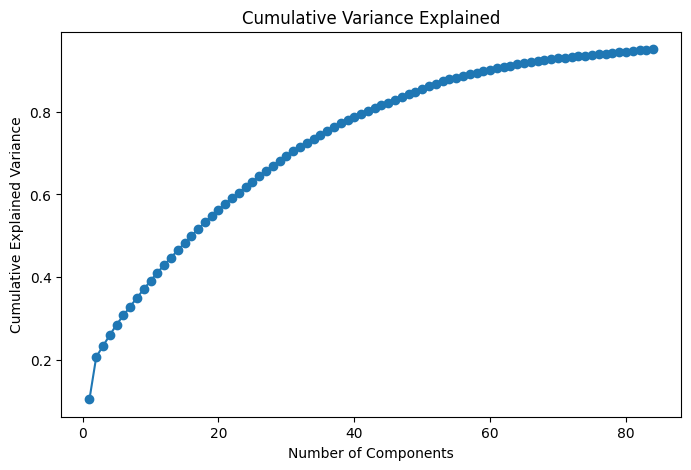

In [43]:
# create new features and show pca variance
plt.figure(figsize=(8,5))
plt.plot(range(1, len(pca.explained_variance_ratio_)+1),
         pca.explained_variance_ratio_.cumsum(), marker='o')
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("Cumulative Variance Explained")
plt.show()

In [44]:
# 2. Import model
from sklearn.model_selection import train_test_split # using 0.2 testing
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV # tuning method
from sklearn.tree import DecisionTreeClassifier # define decision tree
from sklearn.metrics import accuracy_score

In [45]:
X_model = X.copy()
y_model =y.copy()

In [46]:
# Split data for validation and test score is 0.2
X_train, X_test, y_train, y_test = train_test_split( X_model, y_model, test_size=0.2, stratify=y_model, random_state=42)

In [47]:
# Define the Decision Tree model
dt = DecisionTreeClassifier()
dt.fit(X_train, y_train)

DecisionTreeClassifier()

In [48]:
# GridSearchCV for parameter tuning (5-fold cross-validation)
param_grid_dt = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [None, 5, 10, 20],
    'min_samples_split': [2, 5, 10]
}

 # check 5-fold cross-validation
grid_dt = GridSearchCV(
    estimator=dt,
    param_grid=param_grid_dt,
    cv=5, # 5 fold cross validation
    scoring='accuracy',
    n_jobs=-1
)
# Fit model
grid_dt.fit(X_train, y_train)

# Evaluation metrics
print("Best Parameters (Decision Tree):", grid_dt.best_params_)
print("Best Cross-Validation Accuracy:", grid_dt.best_score_)

# Predictions
y_pred_dt = grid_dt.best_estimator_.predict(X_test)
# Evaluation metrics
print("Test Accuracy:", accuracy_score(y_test, y_pred_dt))

Best Parameters (Decision Tree): {'criterion': 'entropy', 'max_depth': 5, 'min_samples_split': 2}
Best Cross-Validation Accuracy: 0.5006123941996968
Test Accuracy: 0.5186567164179104


In [49]:
# Define the hyperparameter search space for Decision Tree
param_dist_dt = {
    'criterion': ['gini', 'entropy'], #measures the quality of a split.
    'max_depth': [None, 5, 10, 15, 20, 25], # how deep the tree can grow
    'min_samples_split': [2, 5, 10, 15] #minimum number of samples
}

 # Initialize RandomizedSearchCV
rand_dt = RandomizedSearchCV(
    estimator=dt,
    param_distributions=param_dist_dt,
    n_iter=10,  # number of random combinations to test
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    random_state=42
)
# Fit the RandomizedSearchCV on training data
rand_dt.fit(X_train, y_train)

# Evaluation metrics
print("Best Parameters (Decision Tree):", rand_dt.best_params_)
print("Best CV Accuracy:", rand_dt.best_score_)

# Predictions
y_pred_dt = rand_dt.best_estimator_.predict(X_test)
# Evaluation metrics
print("Test Accuracy:", accuracy_score(y_test, y_pred_dt))

Best Parameters (Decision Tree): {'min_samples_split': 2, 'max_depth': 15, 'criterion': 'gini'}
Best CV Accuracy: 0.5000033914235742
Test Accuracy: 0.5360696517412935


In [50]:
#Decision Tree: Compare GridSearchCV vs RandomizedSearchCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

print("Decision Tree Evaluation Comparison")
print("=" * 60)

#Best Models from GridSearchCV and RandomizedSearchCV
best_dt_grid = grid_dt.best_estimator_
best_dt_random = rand_dt.best_estimator_

#GridSearchCV Best Model
y_pred_dt_grid = best_dt_grid.predict(X_test)
y_prob_dt_grid = best_dt_grid.predict_proba(X_test)[:, 1]

print("\nGridSearchCV Results:")
print("Accuracy :", accuracy_score(y_test, y_pred_dt_grid))
print("Precision:", precision_score(y_test, y_pred_dt_grid))
print("Recall   :", recall_score(y_test, y_pred_dt_grid))
print("F1 Score :", f1_score(y_test, y_pred_dt_grid))
print("AUC Score:", roc_auc_score(y_test, y_prob_dt_grid))

#RandomizedSearchCV Best Model
y_pred_dt_random = best_dt_random.predict(X_test)
y_prob_dt_random = best_dt_random.predict_proba(X_test)[:, 1]

print("\nRandomizedSearchCV Results:")
print("Accuracy :", accuracy_score(y_test, y_pred_dt_random))
print("Precision:", precision_score(y_test, y_pred_dt_random))
print("Recall   :", recall_score(y_test, y_pred_dt_random))
print("F1 Score :", f1_score(y_test, y_pred_dt_random))
print("AUC Score:", roc_auc_score(y_test, y_prob_dt_random))


Decision Tree Evaluation Comparison

GridSearchCV Results:
Accuracy : 0.5186567164179104
Precision: 0.511049723756906
Recall   : 0.9181141439205955
F1 Score : 0.6566104702750666
AUC Score: 0.5226728464199304

RandomizedSearchCV Results:
Accuracy : 0.5360696517412935
Precision: 0.5273722627737226
Recall   : 0.71712158808933
F1 Score : 0.6077812828601472
AUC Score: 0.5376570979499143


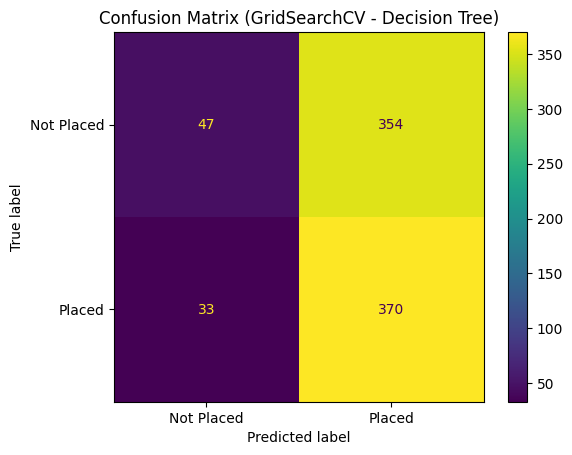

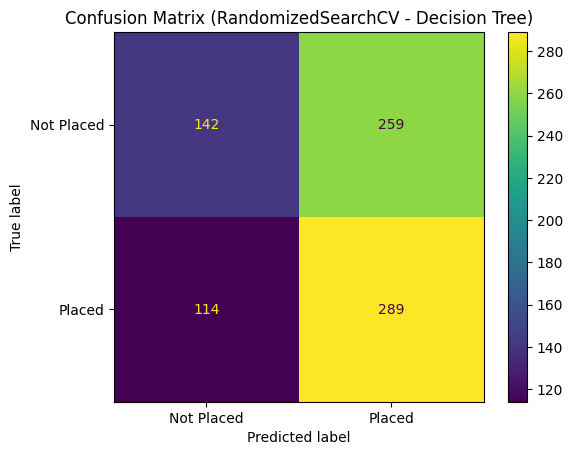

In [51]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_curve
import matplotlib.pyplot as plt

# Confusion Matrix for GridSearchCV decision tree Model
cm_grid = confusion_matrix(y_test, y_pred_dt_grid)
disp_grid = ConfusionMatrixDisplay(confusion_matrix=cm_grid, display_labels=['Not Placed', 'Placed'])
disp_grid.plot()
plt.title('Confusion Matrix (GridSearchCV - Decision Tree)')
plt.show()

# Confusion Matrix for RandomizedSearchCV decision tree Model
cm_random = confusion_matrix(y_test, y_pred_dt_random)
disp_random = ConfusionMatrixDisplay(confusion_matrix=cm_random, display_labels=['Not Placed', 'Placed'])
disp_random.plot()
plt.title('Confusion Matrix (RandomizedSearchCV - Decision Tree)')
plt.show()